In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 01. Geometry of flat-sliced de Sitter space

Goal: build the background in both coordinate systems, derive the relation between cosmic and conformal time,
and verify -- by direct computation with the conventions of `docs/conventions.md` -- the constant-curvature identity
$R_{\mu\nu\rho\sigma}=H^2(g_{\mu\rho}g_{\nu\sigma}-g_{\mu\sigma}g_{\nu\rho})$, the Einstein tensor and the curvature invariants.
Every sign is checked against the implementation, including a negative control with a deliberately flipped Riemann sign.

In [2]:
from desitter_perturbations import background as bg
from desitter_perturbations.symbolic.curvature import Geometry
from desitter_perturbations.symbolic.einstein_tensor import einstein_tensor, field_equation
b = bg.symbolic_background(); H = b["H"]
print("a(t) =", b["a_t"], "   a(eta) =", b["a_eta"], "   calH =", b["calH"])
print("residuals of d eta/dt = 1/a and a(eta(t)) = exp(Ht):", bg.verify_time_relation())

a(t) = exp(H*t)    a(eta) = -1/(H*eta)    calH = -1/eta
residuals of d eta/dt = 1/a and a(eta(t)) = exp(Ht): (0, 0)


In [3]:
rows = []
for name, key, coords in (("cosmic", "g_cosmic", b["coords_cosmic"]), ("conformal", "g_conformal", b["coords_conformal"])):
    G = Geometry(coords, b[key])
    res = G.constant_curvature_residual(H)
    rows.append((name, G.ricci_scalar, G.ricci_squared(), G.kretschmann(),
                 all(v == 0 for v in res.values()), field_equation(G, 3*H**2) == sp.zeros(4,4)))
for r in rows: print(r)

('cosmic', 12*H**2, 36*H**4, 24*H**4, True, True)
('conformal', 12*H**2, 36*H**4, 24*H**4, True, True)


Sign convention test: with the Riemann sign flipped the Ricci scalar becomes $-12H^2$; the test suite treats that as a *detected* error.

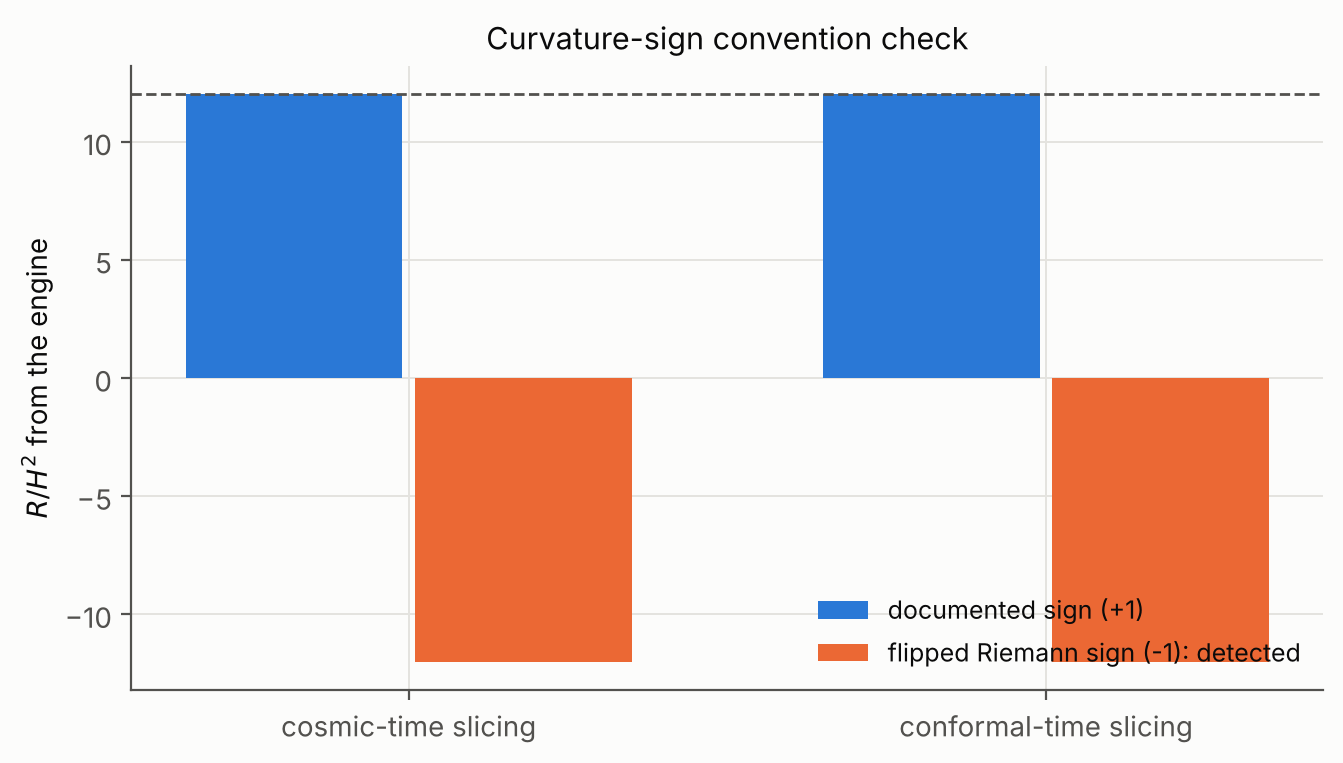

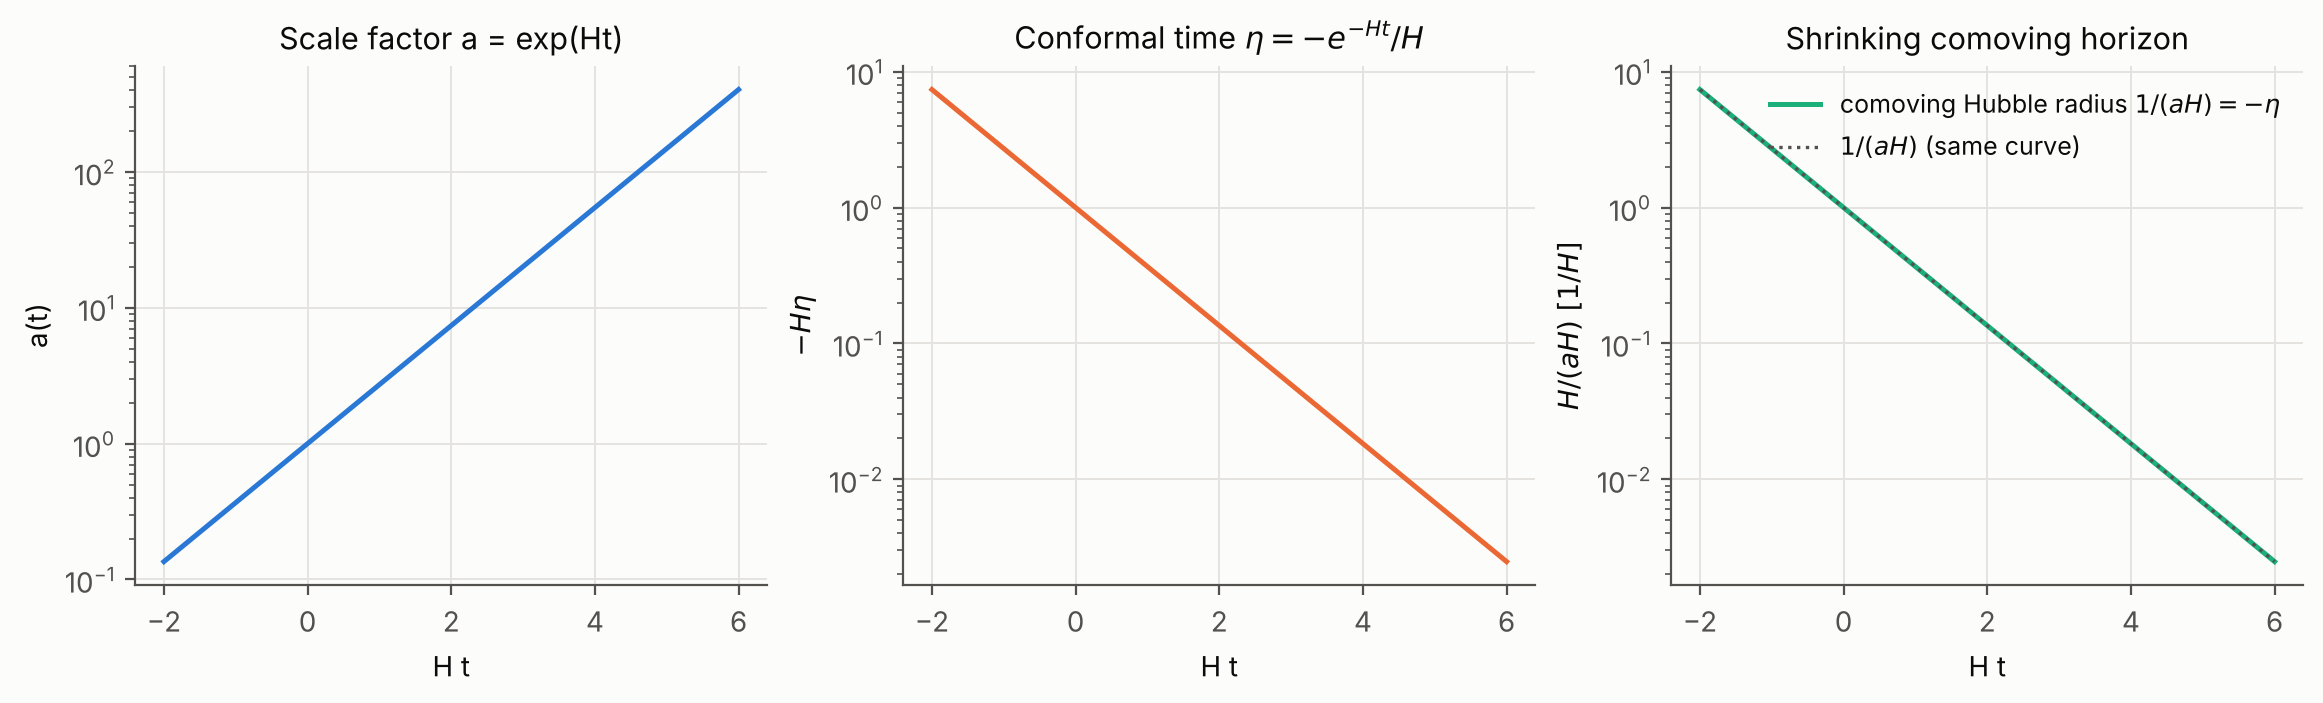

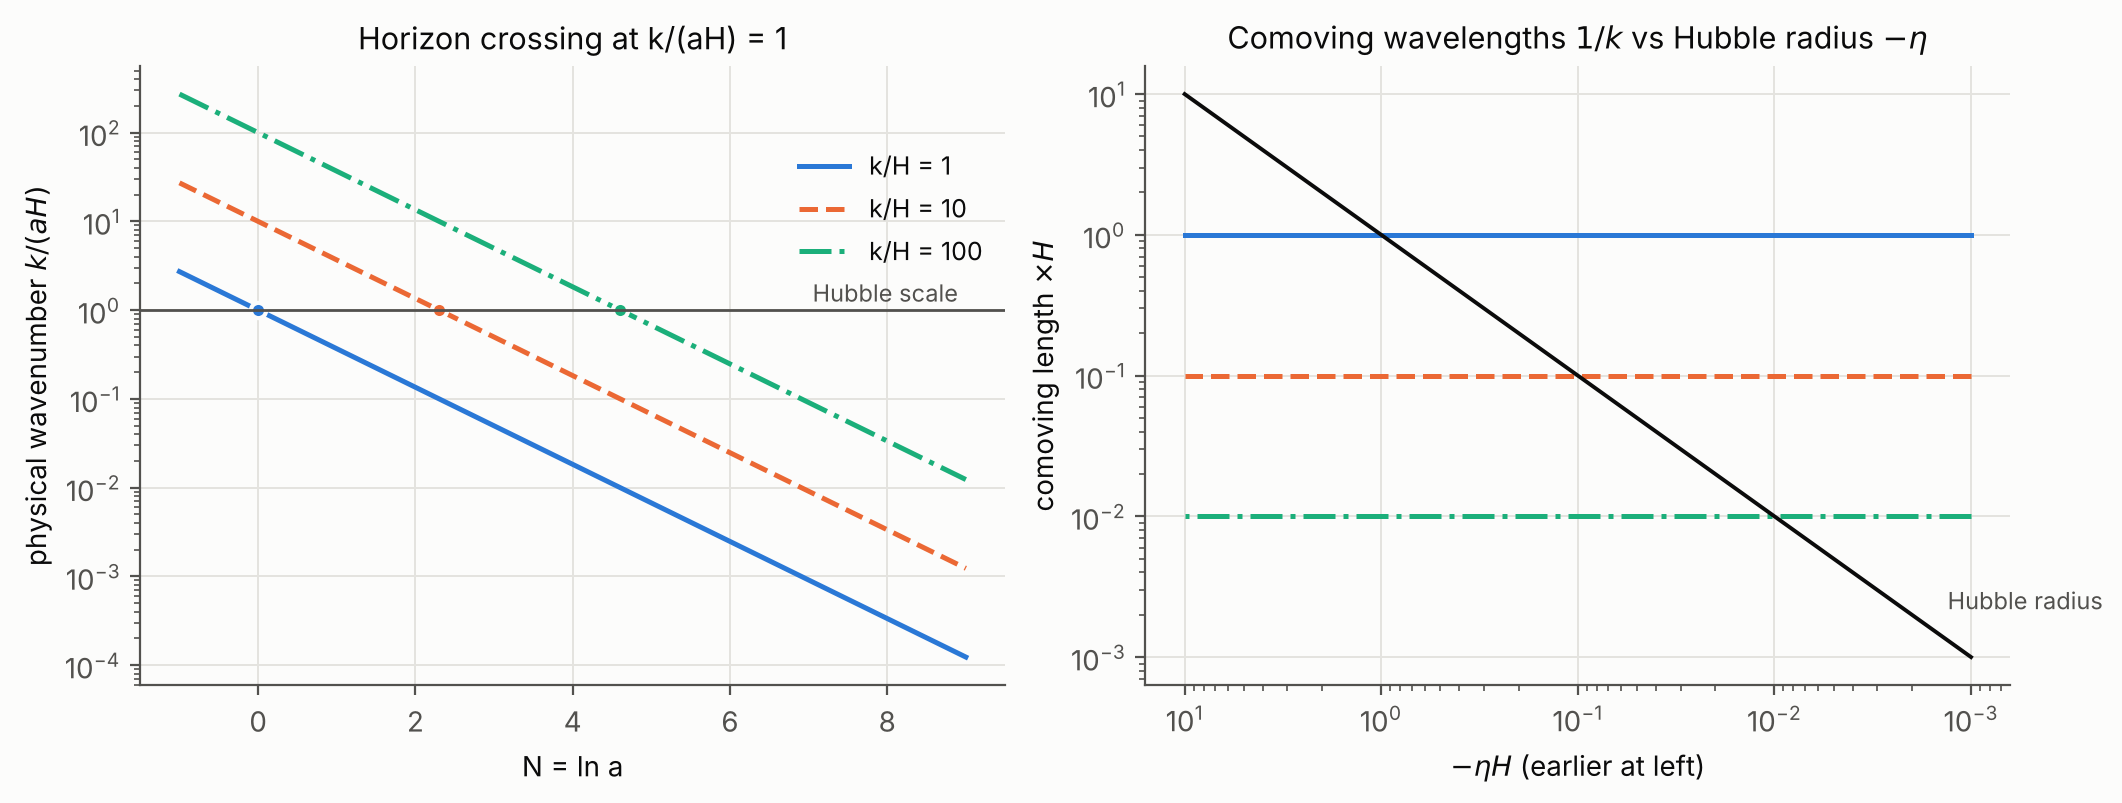

In [4]:
from desitter_perturbations.visualization import geometry_plots as gp, background_plots as bp
show(gp.plot_curvature_invariants())
show(bp.plot_background_evolution())
show(bp.plot_horizon_crossing())

Embedding check: flat slicing is the hyperboloid $-X_0^2+\mathbf X^2+X_4^2=1/H^2$ with
$X_0=\sinh(Ht)/H+\tfrac H2 e^{Ht}r^2$, $X_4=\cosh(Ht)/H-\tfrac H2 e^{Ht}r^2$, $X_i=e^{Ht}x_i$. The induced metric is verified symbolically in
`validation.symbolic_checks.background_checks` (record `bg.embedding`).